## Imports

In [1]:
import pandas as pd
import numpy as np

### Load the dataset

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

#### no of rows and columns, columns naames, data types, non-null values

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


#### first 5 rows:

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### check for duplicates

In [5]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888    False
889    False
890    False
Length: 891, dtype: bool

#### how many duplicated rows?

In [6]:
df.duplicated().sum()

np.int64(0)

#### see the actual duplicated rows:

In [7]:
df[df.duplicated()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


#### .dtype separate categorical and numerical columns

In [11]:
cat_col = df.select_dtypes(include=['object', 'string']).columns.tolist()

num_col = df.select_dtypes(include=['number']).columns.tolist()

print('Categorical columns:', cat_col)
print('Numerical columns:', num_col)

Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


#### count unique values in the categorical columns

In [12]:
df[cat_col].nunique()

Name        891
Sex           2
Ticket      681
Cabin       147
Embarked      3
dtype: int64

#### count unique values in the numerical columns

In [13]:
df[num_col].nunique()

PassengerId    891
Survived         2
Pclass           3
Age             88
SibSp            7
Parch            7
Fare           248
dtype: int64

#### calculate missing values as %

In [14]:
round((df.isnull().sum() / df.shape[0]) * 100, 2)

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

#### drop irrelevant or data-heavy missing columns

In [16]:
df1 = df.drop(columns=["Name", "Ticket", "Cabin"])
df1 = df1.dropna(subset=["Embarked"])
df1["Age"] = df1["Age"].fillna(df1["Age"].mean())

#### Detect Outliers with Box Plot

/var/folders/v_/70wdhjs53ylbyj_44k3d8p4r0000gn/T/ipykernel_43253/4034359996.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df1["Age"], vert=False)


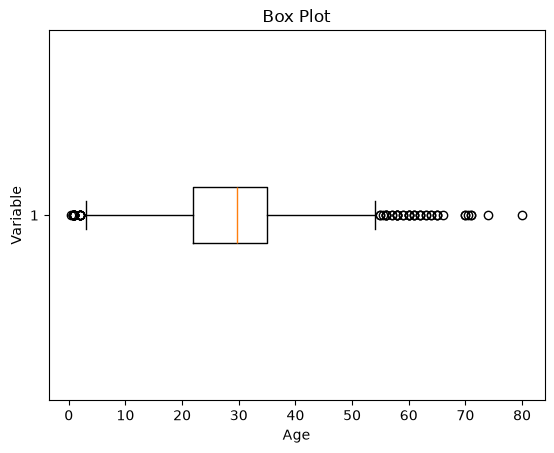

In [17]:
import matplotlib.pyplot as plt

plt.boxplot(df1["Age"], vert=False)
plt.ylabel("Variable")
plt.xlabel("Age")
plt.title("Box Plot")
plt.show()

#### calculate outlier boundaries and removed them

In [20]:
mean = df1["Age"].mean()
std = df1["Age"].std()

lower_bound = mean - 2 * std
upper_bound = mean + 2 * std

df2 = df1[(df1["Age"] >= lower_bound) & (df1["Age"] <= upper_bound)]

#### input missing data again if any

In [19]:
df3 = df2.fillna(df2["Age"].mean())
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

#### recalculated outlier bounds and remove outliers from the updated data

In [21]:
mean = df3['Age'].mean()
std = df3['Age'].std()

lower_bound = mean - 2 * std
upper_bound = mean + 2 * std

print('Lower Bound :', lower_bound)
print('Upper Bound :', upper_bound)

df4 = df3[(df3['Age'] >= lower_bound) & (df3['Age'] <= upper_bound)]

Lower Bound : 8.978989004171453
Upper Bound : 49.30395961288914


#### data validation and verification

In [22]:
X = df3[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]]
Y = df3["Survived"]

#### data formatting

In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))

num_col_ = X.select_dtypes(include="number").columns

x1 = X.copy()

x1[num_col_] = scaler.fit_transform(x1[num_col_])

x1.head()


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1.0,male,0.349515,0.125,0.0,0.014151,S
1,0.0,female,0.660194,0.125,0.0,0.139136,C
2,1.0,female,0.427184,0.000,0.0,0.015469,S
3,0.0,female,0.601942,0.125,0.0,0.103644,S
4,1.0,male,0.601942,0.000,0.0,0.015713,S
